# 根据XYZ坐标自动生成俯仰角-平面拟合

注: 不需要执行此脚本, 除非你需要制定自己的俯仰角生成策略。

## 导入依赖

In [1]:
import math
import numpy as np
import yaml
from matplotlib import pyplot as plt
import scipy, scipy.optimize
# 自定义库
from arm5dof_uservo import Arm5DoFUServo
from config import *

In [392]:
import seaborn

## 创建机械臂

In [2]:
# 创建机械臂
arm = Arm5DoFUServo(is_init_pose=False)

In [3]:
# 设置为阻尼模式
arm.set_damping(1000)

## 样本采集

In [4]:
# 位姿列表
pose_list = []

采集一次样本
在空间中，任意移动夹爪，将夹爪调整到适合夹取的位姿

In [387]:
# 一次追加一个样本
cur_pose = arm.get_tool_pose()
# 将采集到的抓取位姿，添加到位姿列表里面
pose_list.append(cur_pose)

#  打印日志
x6, y6, z6, pitch,roll = cur_pose
print(f"当前位姿: X {x6:.1f} Y {y6:.1f} Z {z6:.1f} Pitch {np.degrees(pitch):.1f}")
print("已采集样本: {}".format(len(pose_list)))

SyntaxError: invalid syntax (3519586990.py, line 8)

## 样本保存

In [388]:
arm_pitch_sample = np.float32(pose_list)
np.savetxt("config/arm_pitch_sample.csv", arm_pitch_sample, delimiter=",")

## 可视化

In [389]:
# X-Y平面上的距离
x0 = np.sqrt(arm_pitch_sample[:, 0]**2 + arm_pitch_sample[:, 1]**2)
# Z
z = arm_pitch_sample[:, 2]
# 俯仰角
pitch = arm_pitch_sample[:, 3]

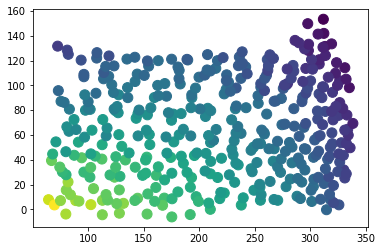

In [390]:
plt.scatter(x0, z, c=pitch, s=100)

投影到3D下看看

<IPython.core.display.Javascript object>


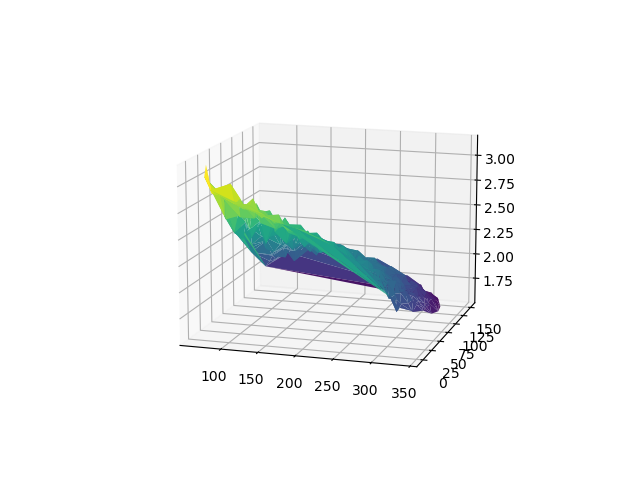

/tmp/ipykernel_15921/3464100442.py:9: MatplotlibDeprecationWarning: Calling gca() with keyword arguments was deprecated in Matplotlib 3.4. Starting two minor releases later, gca() will take no keyword arguments. The gca() function should only be used to get the current axes, or if no axes exist, create new axes with default keyword arguments. To create a new axes with non-default arguments, use plt.axes() or plt.subplot().
  ax = fig.gca(projection='3d')


In [394]:
%matplotlib notebook
# libraries
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
 
fig = plt.figure()
ax = fig.gca(projection='3d')
ax.plot_trisurf(x0, z, pitch, cmap=plt.cm.viridis, linewidth=0.2)
plt.show()

## 平面拟合

In [397]:
def func(data, a, b, c):
    x0 = data[0]
    z = data[1]
    return a*x0 + b*z + c

# 初始值
initial_parameter = [1.0, 1.0, 1.0]
# 拟合结果
fitted_parameters, pcov = scipy.optimize.curve_fit(func, [x0, z], pitch, p0 = initial_parameter)

a, b, c = fitted_parameters
print(f"pitch = {a:.6f}*x0 + {b:.6f}*z + {c:.6f}")

pitch = -0.002490*x0 + -0.004985*z + 3.048636


In [398]:
print(f"PITCH_PANEL_A = {a:.6f}")
print(f"PITCH_PANEL_B = {b:.6f}")
print(f"PITCH_PANEL_C = {c:.6f}")

PITCH_PANEL_A = -0.002490
PITCH_PANEL_B = -0.004985
PITCH_PANEL_C = 3.048636


## 保存拟合结果

修改`conifg.py`里面的ABC的取值
```python
# Pitch平面拟合结果
PITCH_PANEL_A = -0.0034
PITCH_PANEL_B = -0.0047
PITCH_PANEL_C = 2.8721
```